<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6_ap_pingpong.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio VI, apêndice: a bola de pingue-pongue com efeito

## A força de Magnus, a rotação da bola como quaternion, e medir o efeito com uma câmera rápida sem se enganar de sentido

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Anterior:** [X6_quaternions.ipynb](X6_quaternions.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6_quaternions.ipynb))

**O efeito.** No tênis de mesa, a bola gira depressa: um *topspin* forte passa de 50 rotações por segundo, e os melhores jogadores chegam perto de 150. A rotação desvia a trajetória pela **força de Magnus**: a bola com *topspin* mergulha, a com *backspin* (corte) "flutua". Para um robô jogador, ou para a análise de jogos, é preciso medir a rotação. As câmeras rápidas fazem isso acompanhando a **marca impressa** na bola: a orientação da marca em cada quadro é um quaternion, e a rotação entre quadros dá a velocidade angular.

**O modelo** (simples, com coeficientes típicos e aproximados): bola de 2,7 g e raio 20 mm, com arrasto e Magnus,

$$m\dot{\mathbf v}=m\mathbf g-\tfrac12\rho AC_D\,\lvert\mathbf v\rvert\,\mathbf v+\tfrac12\rho AC_L\,r\,(\boldsymbol\omega\times\mathbf v),\qquad \dot q=\tfrac12\,(0,\boldsymbol\omega)\otimes q,$$

com $C_D=0{,}5$ e $C_L=0{,}3$. Os valores medidos na literatura variam com a velocidade e com a rotação; este notebook usa constantes. A rotação $\boldsymbol\omega$ (no mundo) é tratada como constante durante o voo, que dura menos de meio segundo (o atrito do ar a reduz devagar). Com $\boldsymbol\omega$ constante no mundo, a orientação é exata: $q(t)=\mathrm{Exp}(\boldsymbol\omega t)\,q_0$.

**O que este notebook mostra.**
1. Três saques com a mesma velocidade inicial: sem efeito, com *topspin* e com corte.
2. Medir a rotação pela marca, com câmeras de várias velocidades, e o **serrilhado** (*aliasing*) em $SO(3)$: abaixo de dois quadros por rotação, a câmera vê a bola girar para o lado errado.
3. O efeito do erro de medida da rotação no ponto onde a bola quica.

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

def qmul(a, b):
    """Produto de Hamilton de quaternions guardados como arrays (w, x, y, z); aceita pilhas (..., 4)."""
    a, b = np.asarray(a), np.asarray(b)
    w1, x1, y1, z1 = np.moveaxis(a, -1, 0); w2, x2, y2, z2 = np.moveaxis(b, -1, 0)
    return np.stack([w1 * w2 - x1 * x2 - y1 * y2 - z1 * z2,
                     w1 * x2 + x1 * w2 + y1 * z2 - z1 * y2,
                     w1 * y2 - x1 * z2 + y1 * w2 + z1 * x2,
                     w1 * z2 + x1 * y2 - y1 * x2 + z1 * w2], axis=-1)

def qconj(q):
    q = np.asarray(q); return q * np.array([1, -1, -1, -1])

def qnorm(q):
    q = np.asarray(q, float); return q / np.linalg.norm(q, axis=-1, keepdims=True)

def qrot(q, v):
    """O vetor v (3,) levado pela rotação q: a parte vetorial de q (0, v) q*."""
    return qmul(qmul(q, np.concatenate([[0.0], v])), qconj(q))[1:]

def qmat(q):
    """A matriz de rotação R(q), com R v = q v q* (q unitário)."""
    w, x, y, z = q
    return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - w * z), 2 * (x * z + w * y)],
                     [2 * (x * y + w * z), 1 - 2 * (x * x + z * z), 2 * (y * z - w * x)],
                     [2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x * x + y * y)]])

def mat_q(R):
    """De uma matriz de rotação para um quaternion (método de Shepperd: usa o maior pivô, sem perder dígitos)."""
    t = np.trace(R); d = np.diag(R)
    k = np.argmax([t, *d])
    if k == 0:
        w = np.sqrt(1 + t) / 2; q = [w, (R[2, 1] - R[1, 2]) / (4 * w), (R[0, 2] - R[2, 0]) / (4 * w), (R[1, 0] - R[0, 1]) / (4 * w)]
    elif k == 1:
        x = np.sqrt(1 + 2 * d[0] - t) / 2; q = [(R[2, 1] - R[1, 2]) / (4 * x), x, (R[0, 1] + R[1, 0]) / (4 * x), (R[0, 2] + R[2, 0]) / (4 * x)]
    elif k == 2:
        y = np.sqrt(1 + 2 * d[1] - t) / 2; q = [(R[0, 2] - R[2, 0]) / (4 * y), (R[0, 1] + R[1, 0]) / (4 * y), y, (R[1, 2] + R[2, 1]) / (4 * y)]
    else:
        z = np.sqrt(1 + 2 * d[2] - t) / 2; q = [(R[1, 0] - R[0, 1]) / (4 * z), (R[0, 2] + R[2, 0]) / (4 * z), (R[1, 2] + R[2, 1]) / (4 * z), z]
    q = np.array(q); return q if q[0] >= 0 else -q

def qexp(phi):
    """Exp do vetor de rotação φ = θ n: (cos(θ/2), sen(θ/2) n), com o sinc estável perto de θ = 0."""
    phi = np.asarray(phi, float); th = np.linalg.norm(phi)
    return np.concatenate([[np.cos(th / 2)], 0.5 * sinc(th / 2) * phi])

def qlog(q):
    """Log: o vetor de rotação φ de q (escolhendo o representante com w ≥ 0, isto é, |θ| ≤ π)."""
    q = np.asarray(q, float)
    if q[0] < 0: q = -q
    s = np.linalg.norm(q[1:]); th = 2 * np.arctan2(s, q[0])     # atan2: estável para ângulos pequenos e grandes
    return 2 * q[1:] / sinc(th / 2)

def slerp(q0, q1, s):
    """Interpolação esférica: q0 Exp(s Log(q0* q1)), pelo arco mais curto."""
    return qmul(q0, qexp(s * qlog(qmul(qconj(q0), q1))))

def chapeu(v):
    """A matriz antissimétrica [v]×, com [v]× u = v × u."""
    return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])

rng = np.random.default_rng(67)
M, RB, RHO, CD, CL = 2.7e-3, 0.020, 1.2, 0.5, 0.3
AREA = np.pi * RB**2
G = np.array([0, 0, -9.81])
MESA, REDE_X, REDE_H = 2.74, 1.37, 0.1525

def acel(v, w):
    return G - 0.5 * RHO * AREA * CD * np.linalg.norm(v) * v / M + 0.5 * RHO * AREA * CL * RB * np.cross(w, v) / M

def voa(p0, v0, w, h=1e-4, t_max=1.5):
    """RK4 até a bola tocar a mesa (z = 0); devolve trajetória e o ponto de toque (interpolado)."""
    p, v, P = np.array(p0, float), np.array(v0, float), [np.array(p0, float)]
    for _ in range(int(t_max / h)):
        k1v = acel(v, w); k1p = v
        k2v = acel(v + h / 2 * k1v, w); k2p = v + h / 2 * k1v
        k3v = acel(v + h / 2 * k2v, w); k3p = v + h / 2 * k2v
        k4v = acel(v + h * k3v, w); k4p = v + h * k3v
        pn = p + h / 6 * (k1p + 2 * k2p + 2 * k3p + k4p); v = v + h / 6 * (k1v + 2 * k2v + 2 * k3v + k4v)
        if pn[2] <= 0:
            f_ = p[2] / (p[2] - pn[2]); P.append(p + f_ * (pn - p)); return np.array(P), P[-1]
        p = pn; P.append(p)
    return np.array(P), None

def rps(n): return 2 * np.pi * n                   # rotações por segundo → rad/s

## 1. Três saques

A bola sai de 30 cm acima da borda da mesa, a 8 m/s, 6° acima da horizontal, na direção $+x$. O *topspin* gira em torno de $+y$ (a parte de cima da bola anda para a frente) e o corte em torno de $-y$, ambos a 50 rotações por segundo. A mesa tem 2,74 m.

OK   sem ar, a bola toca onde a parábola diz:  diferença máxima = 3.22e-08


sem efeito        : passa  12.6 cm acima da rede;  toca o plano da mesa em x = 2.368 m (dentro da mesa)


topspin (50 rps)  : passa   5.9 cm acima da rede;  toca o plano da mesa em x = 1.963 m (dentro da mesa)


corte (50 rps)    : passa  19.1 cm acima da rede;  toca o plano da mesa em x = 3.057 m (FORA da mesa)
força de Magnus no início: 11.4 mN, 0.4 vezes o peso da bola
OK   o topspin faz a bola quicar antes; o corte, depois:  diferença máxima = 0.00e+00


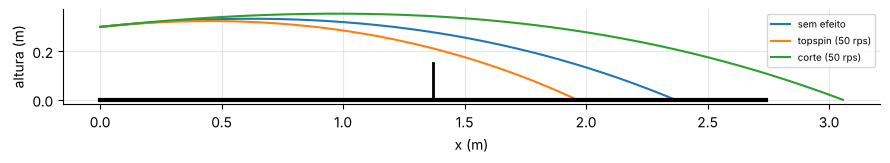

In [2]:
p0 = np.array([0.0, 0.0, 0.30]); ang = np.radians(6.0)
v0 = 8.0 * np.array([np.cos(ang), 0, np.sin(ang)])
# conferência: sem ar (ρ = 0), a trajetória é a parábola
RHO_salvo = RHO; RHO = 0.0
_, toque_vacuo = voa(p0, v0, np.zeros(3))
RHO = RHO_salvo
t_ = (v0[2] + np.sqrt(v0[2]**2 + 2 * 9.81 * p0[2])) / 9.81
confere("sem ar, a bola toca onde a parábola diz", toque_vacuo[0], v0[0] * t_, tol=1e-6)

saques = {"sem efeito": np.zeros(3), "topspin (50 rps)": np.array([0, rps(50), 0]), "corte (50 rps)": np.array([0, -rps(50), 0])}
traj = {}
for nome, w in saques.items():
    P, toque = voa(p0, v0, w); traj[nome] = P
    z_rede = np.interp(REDE_X, P[:, 0], P[:, 2])
    print(f"{nome:18s}: passa {100 * (z_rede - REDE_H):5.1f} cm acima da rede;  toca o plano da mesa em x = {toque[0]:.3f} m "
          f"({'dentro' if toque[0] <= MESA else 'FORA'} da mesa)")
f_magnus = 0.5 * RHO * AREA * CL * RB * rps(50) * 8.0
print(f"força de Magnus no início: {1000 * f_magnus:.1f} mN, {f_magnus / (M * 9.81):.1f} vezes o peso da bola")
confere("o topspin faz a bola quicar antes; o corte, depois", traj["topspin (50 rps)"][-1, 0] < traj["sem efeito"][-1, 0] < traj["corte (50 rps)"][-1, 0], True)

fig, ax = plt.subplots(figsize=(9, 3))
for nome, P in traj.items(): ax.plot(P[:, 0], P[:, 2], label=nome)
ax.plot([0, MESA], [0, 0], "k-", lw=3); ax.plot([REDE_X, REDE_X], [0, REDE_H], "k-", lw=2)
ax.set_xlabel("x (m)"); ax.set_ylabel("altura (m)"); ax.set_aspect("equal"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 2. Medir a rotação pela marca

A câmera vê a marca da bola a cada $\Delta t=1/f$ segundos, e um algoritmo de visão estima a orientação dela, com erro de uns 3° por eixo. Entre dois quadros, a rotação é $\Delta q_k=q_{k+1}q_k^*=\mathrm{Exp}(\boldsymbol\omega\Delta t)$ (com ruído), e uma estimativa simples é a média de $\mathrm{Log}(\Delta q_k)/\Delta t$ sobre os quadros dos primeiros 40 ms.

O $\mathrm{Log}$ devolve sempre o giro **mais curto**, de no máximo 180°. Se a bola girar mais que meia volta entre dois quadros, a câmera não tem como saber: 240° para a frente e 120° para trás dão a mesma marca. É o teorema da amostragem de Nyquist, agora em $SO(3)$: a câmera precisa de mais de **dois quadros por rotação**.

In [3]:
w_ver = np.array([0, rps(50), 0])
q0 = qnorm(rng.normal(size=4))
def estima(fps, janela=0.04, sig=np.radians(3), rng_=rng):
    n_quadros = int(round(janela * fps)) + 1; ts = np.arange(n_quadros) / fps
    qs = [qmul(qmul(qexp(w_ver * t), q0), qexp(sig * rng_.normal(size=3))) for t in ts]
    return np.mean([qlog(qmul(qs[k_ + 1], qconj(qs[k_]))) for k_ in range(n_quadros - 1)], axis=0) * fps

print(" quadros/s   graus por quadro   rotação estimada (rps, em torno de y)   erro do eixo")
estimativas = {}
for fps in [2000, 1000, 250, 120, 75]:
    w_est = estima(fps); estimativas[fps] = w_est
    eixo = np.degrees(np.arccos(abs(w_est @ w_ver) / (np.linalg.norm(w_est) * np.linalg.norm(w_ver))))
    print(f"{fps:8d}        {360 * 50 / fps:6.1f}°            {w_est[1] / (2 * np.pi):+8.2f}                        {eixo:5.2f}°")
confere("acima de 2 quadros por rotação, a estimativa erra menos de 3%", all(abs(estimativas[f][1] / w_ver[1] - 1) < 0.03 for f in [2000, 1000, 250, 120]), True)
confere("a 75 quadros/s (1,5 por rotação), a câmera vê −25 rps: o topspin parece corte", estimativas[75][1] / (2 * np.pi), -25, tol=2)

 quadros/s   graus por quadro   rotação estimada (rps, em torno de y)   erro do eixo
    2000           9.0°              +49.86                         0.33°
    1000          18.0°              +49.60                         0.53°
     250          72.0°              +50.26                         1.53°
     120         150.0°              +49.30                         1.76°
      75         240.0°              -25.31                         4.30°
OK   acima de 2 quadros por rotação, a estimativa erra menos de 3%:  diferença máxima = 0.00e+00
OK   a 75 quadros/s (1,5 por rotação), a câmera vê −25 rps: o topspin parece corte:  diferença máxima = 3.10e-01


## 3. Do erro da rotação ao ponto do quique

Com a rotação estimada, o robô prevê onde a bola vai quicar. Quanto o erro de medida da rotação pesa? Monte Carlo: 300 estimativas a 1000 quadros/s (40 ms de observação), cada uma usada para prever o quique. E o resultado com a estimativa serrilhada de 75 quadros/s.

In [4]:
_, toque_ver = voa(p0, v0, w_ver)
toques = []
for _ in range(300):
    _, tq = voa(p0, v0, estima(1000), h=4e-4); toques.append(tq[:2])
toques = np.array(toques)
_, tq_75 = voa(p0, v0, estimativas[75])
print(f"quique verdadeiro: x = {toque_ver[0]:.3f} m")
print(f"com a rotação medida a 1000 quadros/s: desvio-padrão do quique {100 * toques[:, 0].std():.2f} cm em x, {100 * toques[:, 1].std():.2f} cm em y;  "
      f"média deslocada de {100 * (toques[:, 0].mean() - toque_ver[0]):+.2f} cm")
print(f"com a rotação serrilhada de 75 quadros/s: o robô prevê o quique em x = {tq_75[0]:.3f} m, {100 * (tq_75[0] - toque_ver[0]):+.0f} cm do verdadeiro")
confere("a 1000 quadros/s, o quique é previsto com desvio abaixo de 1 cm", toques[:, 0].std() < 0.01, True)
confere("com a medida serrilhada, o erro passa de 20 cm", abs(tq_75[0] - toque_ver[0]) > 0.2, True)

quique verdadeiro: x = 1.963 m
com a rotação medida a 1000 quadros/s: desvio-padrão do quique 0.20 cm em x, 0.14 cm em y;  média deslocada de +0.03 cm
com a rotação serrilhada de 75 quadros/s: o robô prevê o quique em x = 2.666 m, +70 cm do verdadeiro
OK   a 1000 quadros/s, o quique é previsto com desvio abaixo de 1 cm:  diferença máxima = 0.00e+00
OK   com a medida serrilhada, o erro passa de 20 cm:  diferença máxima = 0.00e+00


**Leitura.** Com a mesma batida, a rotação muda tudo: sem efeito, a bola quica a 2,37 m; com *topspin* de 50 rps, a força de Magnus (0,4 vez o peso da bola) a puxa para baixo e ela quica a 1,96 m, passando mais rente à rede; com corte, a mesma força a sustenta, e ela sai da mesa (toca o plano da mesa a 3,06 m). É por isso que o jogador muda a batida conforme o efeito.

Medindo a rotação pela marca, com uma janela de 40 ms, a estimativa erra menos de 2% em todas as câmeras com mais de dois quadros por rotação, inclusive a de 120 quadros/s, em que a bola gira 150° entre quadros. A precisão depende da **janela**, não do número de quadros: a média das rotações entre quadros vizinhos é, praticamente, a rotação total dividida pelo tempo total, e o ruído das orientações intermediárias se cancela. A 75 quadros/s, a bola gira 240° entre quadros, o $\mathrm{Log}$ escolhe os $-120°$, e a câmera vê **−25 rps**: um *topspin* de 50 rps medido como corte de 25 rps. Usada para prever o quique, essa medida erra o ponto em 70 cm; a medida correta, a 1000 quadros/s, prevê o quique com desvio de 2 mm. O serrilhado é a dupla cobertura do notebook VI(a) de novo: a orientação de um quadro não diz quantas voltas inteiras (nem quantas meias voltas, para o $\mathrm{Log}$) a bola deu desde o quadro anterior.

## Exercícios

1. **Efeito lateral.** Um saque com rotação em torno do eixo vertical (efeito lateral) desvia a bola para o lado. Calcule o desvio no quique para 60 rps e confira o sentido com a regra da mão direita em $\boldsymbol\omega\times\mathbf v$.
2. **Mais quadros ou mais câmeras?** Com 250 quadros/s, a 100 rps a câmera ainda acerta; a 130 rps já não. Mostre que duas câmeras de 250 quadros/s **defasadas de meio quadro** equivalem a uma de 500 quadros/s, desde que a orientação venha das duas no mesmo referencial.
3. **Ajuste no grupo.** Em vez da média dos $\mathrm{Log}(\Delta q_k)$, ajuste $q_0$ e $\boldsymbol\omega$ minimizando $\sum_k\lvert\mathrm{Log}\big((\mathrm{Exp}(\boldsymbol\omega t_k)q_0)^*q_k\big)\rvert^2$ por Gauss–Newton no grupo (notebook V(b) e o apêndice de SLAM do domínio V). Com a mesma janela de 40 ms, quanto o desvio da estimativa diminui?
4. **O quique.** No quique, o atrito com a mesa troca parte da rotação por velocidade (e vice-versa). Procure um modelo de impacto com atrito (por exemplo, o de rolar sem escorregar no fim do contato) e simule a bola depois do quique, para os três saques.